# Customer Segmentation Analysis using K-Means Clustering

**Prepared by:** Saurabh Shukla
**Email:** saurabhshuklant@gmail.com
**Track:** Data Analytics | Level 1 | Task 2
**Tools:** Python, pandas, scikit-learn (KMeans), matplotlib, seaborn, Jupyter Notebook

## Introduction

An e-commerce company usually has thousands of customers, but treating all of them the same way is expensive and ineffective. A customer who has been shopping for five years and spends heavily needs a very different message from someone who joined recently and barely spends. **Customer segmentation** solves this by grouping customers who behave alike, so each group can get its own marketing strategy.

In this project I use **K-Means clustering**, an unsupervised machine-learning algorithm, to split the customers of an e-commerce company into distinct segments based on how they behave, and then work out what the business should do for each segment.

**Questions I want to answer**

1. Is the data clean and ready for clustering?
2. How much do customers spend, how long do they stay, and how engaged are they?
3. Which behavioural features should be used to build the segments?
4. How many segments (K) does the data support?
5. Who is in each segment, and what marketing action suits each one?

**About the dataset**

The dataset has **500 customers** of an e-commerce company that serves them through both a mobile app and a website.

| Column | Description |
|---|---|
| Email | Customer's email (acts as the unique identifier) |
| Address | Customer's address |
| Avatar | A colour label linked to the customer's profile |
| Time on App | Average time (in minutes) the customer spends on the mobile app |
| Time on Website | Average time (in minutes) the customer spends on the website |
| Length of Membership | Number of years the customer has been a member |
| Yearly Amount Spent | Amount the customer spends per year |

**An important note on the data (and how I adapted the approach)**

The classic segmentation method is **RFM analysis** (Recency, Frequency, Monetary value), which needs order-level data with purchase dates. This dataset does not contain individual orders: there is no purchase date and no order count. So a true RFM cannot be computed. Instead I use an **RFM-style approach built from what the data does contain**:

| RFM idea | Closest available feature |
|---|---|
| Recency / loyalty | **Length of Membership** (how long the customer has stayed with the company) |
| Frequency / engagement | **Time on App** (how actively the customer uses the platform) |
| Monetary | **Yearly Amount Spent** |

Wherever the checklist asks for something the data cannot give directly (average purchase value, purchase frequency, lifetime value), I say clearly which proxy I used and why.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 13
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

RANDOM_STATE = 42   # fixed so the clusters are reproducible every time the notebook runs
print('Libraries loaded.')

Libraries loaded.


## 1. Loading the Data and Inspecting Its Structure

In [2]:
df = pd.read_csv('data.csv')
print('Shape of the dataset (rows, columns):', df.shape)
print()
print('Column names exactly as read from the file:')
print(df.columns.tolist())
df.head()

Shape of the dataset (rows, columns): (500, 7)

Column names exactly as read from the file:
['\tEmail', 'Address', 'Avatar', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']


,Email,Address,Avatar,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank TunnelWrightmouth, MI 82180-9605",Violet,12.66,39.58,4.08,587.95
1,hduke@hotmail.com,"4547 Archer CommonDiazchester, CA 06566-8576",DarkGreen,11.11,37.27,2.66,392.20
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582Cobbborough, DC 99414-7564",Bisque,11.33,37.11,4.10,487.55
3,riverarebecca@gmail.com,"1414 David ThroughwayPort Jason, OH 22070-1220",SaddleBrown,13.72,36.72,3.12,581.85
4,mstephens@davidson-herman.com,"14023 Rodriguez PassagePort Jacobville, PR 37242-1057",MediumAquaMarine,12.80,37.54,4.45,599.41


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   	Email                500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Time on App           500 non-null    float64
 4   Time on Website       500 non-null    float64
 5   Length of Membership  500 non-null    float64
 6   Yearly Amount Spent   500 non-null    float64
dtypes: float64(4), str(3)
memory usage: 27.5 KB


**Observations**

- The dataset has **500 rows and 7 columns**: 3 text columns (Email, Address, Avatar) and 4 numeric columns.
- Look closely at the column names printed above. The first one is `'\tEmail'`, not `'Email'`. There is a **hidden tab character** stuck to the front of the name, which is an inconsistency in the file. If I left it as it is, `df['Email']` would raise an error. I fix this in the cleaning step below.

### Cleaning and consistency checks

In [4]:
# 1. Fix the column name that has a hidden tab character in it
df.columns = df.columns.str.strip()
print('Cleaned column names:', df.columns.tolist())
print()

# 2. Standardise the text columns (remove stray spaces, make emails lowercase)
df['Email'] = df['Email'].str.strip().str.lower()
df['Address'] = df['Address'].str.strip()
df['Avatar'] = df['Avatar'].str.strip()

# 3. Missing values and duplicates
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows             :', df.duplicated().sum())
print('Duplicate emails           :', df['Email'].duplicated().sum())
print('Emails with spaces in them :', df['Email'].str.contains(r'\s').sum())
print('Unique avatars             :', df['Avatar'].nunique())
print()

# 4. Sanity check on the numeric columns: anything zero or negative?
num_cols = ['Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']
print('Values <= 0 in numeric columns:')
print((df[num_cols] <= 0).sum())

Cleaned column names: ['Email', 'Address', 'Avatar', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']

Missing values per column:
Email                   0
Address                 0
Avatar                  0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

Duplicate rows             : 0
Duplicate emails           : 0
Emails with spaces in them : 0
Unique avatars             : 138

Values <= 0 in numeric columns:
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64


**Observations**

- After removing the hidden tab, the column names are clean and consistent.
- There are **no missing values**, **no duplicate rows** and **no duplicate emails**. Every one of the 500 rows is a different customer.
- There are no zero or negative values in any numeric column, so nothing in the numbers looks like a data-entry error.
- `Avatar` is just a colour name (138 different values) and does not describe customer behaviour. `Address` and `Email` are identifiers. None of these three columns will be used for clustering.
- Since the data was already clean apart from the column name, no rows were dropped and nothing had to be imputed.

## 2. Descriptive Statistics

The checklist asks for **average purchase value, purchase frequency and customer lifetime value**. Because the data has no order-level records, I use the following definitions:

| Metric requested | What I use | Why |
|---|---|---|
| Average purchase value | **Average Yearly Amount Spent** per customer | There is no per-order amount, so annual spend per customer is the closest measure of purchase value |
| Purchase frequency | **Time on App / Time on Website** (engagement) | Order counts are not available, so I measure how actively customers use each channel |
| Customer lifetime value | **CLV (to date) = Yearly Amount Spent x Length of Membership** | An estimate of the total revenue each customer has generated so far, assuming their yearly spending stayed roughly constant |

The CLV is a simple, *historical* estimate. It is not a forecast of future value, but it is good enough to compare segments with each other.

In [5]:
# Customer lifetime value (to date) and total engagement time
df['CLV'] = df['Yearly Amount Spent'] * df['Length of Membership']
df['Total Engagement Time'] = df['Time on App'] + df['Time on Website']

df[num_cols + ['CLV']].describe().round(2)

,Time on App,Time on Website,Length of Membership,Yearly Amount Spent,CLV
count,500.00,500.00,500.00,500.00,500.00
mean,12.05,37.06,3.53,499.31,1828.26
std,0.99,1.01,1.00,79.31,749.84
min,8.51,33.91,0.27,256.67,84.90
25%,11.39,36.35,2.93,445.04,1327.05
50%,11.98,37.07,3.54,498.89,1765.27
75%,12.75,37.72,4.13,549.31,2272.88
max,15.13,40.01,6.92,765.52,5150.00


In [6]:
summary = pd.Series({
    'Number of customers': len(df),
    'Average yearly spend per customer': df['Yearly Amount Spent'].mean(),
    'Median yearly spend per customer': df['Yearly Amount Spent'].median(),
    'Total yearly revenue': df['Yearly Amount Spent'].sum(),
    'Average membership length (years)': df['Length of Membership'].mean(),
    'Average minutes on app': df['Time on App'].mean(),
    'Average minutes on website': df['Time on Website'].mean(),
    'Average CLV to date': df['CLV'].mean(),
    'Median CLV to date': df['CLV'].median(),
    'Total CLV to date': df['CLV'].sum()
}).round(2)
summary.to_frame('Value')

,Value
Number of customers,500.00
Average yearly spend per customer,499.31
Median yearly spend per customer,498.89
Total yearly revenue,249657.12
Average membership length (years),3.53
Average minutes on app,12.05
Average minutes on website,37.06
Average CLV to date,1828.26
Median CLV to date,1765.27
Total CLV to date,914130.73


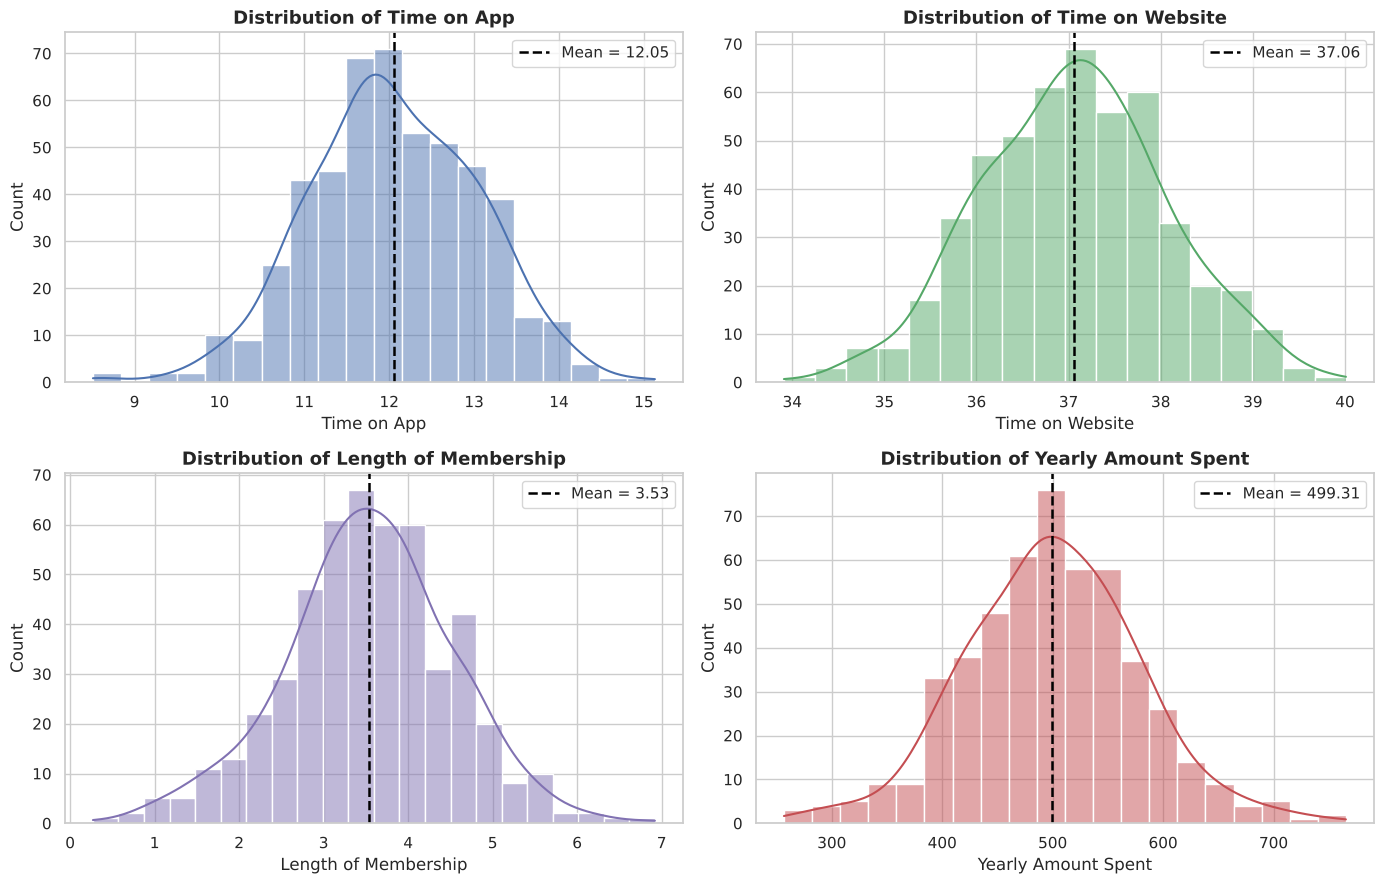

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
colors = ['#4c72b0', '#55a868', '#8172b2', '#c44e52']

for ax, col, c in zip(axes.ravel(), num_cols, colors):
    sns.histplot(df[col], kde=True, ax=ax, color=c, edgecolor='white')
    ax.axvline(df[col].mean(), color='black', ls='--', lw=1.8, label=f'Mean = {df[col].mean():.2f}')
    ax.set_title(f'Distribution of {col}')
    ax.legend()

plt.tight_layout()
plt.show()

**Observations**

- The average customer spends about **499 per year**, and the median (about 499) is almost identical, so spending is symmetrical and not dominated by a few big spenders. Yearly spend ranges from about 257 to 766.
- Customers have been members for about **3.5 years on average**, with a range of 0.3 to 6.9 years.
- Customers spend far more time on the website (about **37 minutes**) than on the app (about **12 minutes**), but, as we will see, the app is the channel that matters for spending.
- All four variables follow a bell-shaped (normal-looking) distribution. There are no heavy skews, which is good news for K-Means because it works best on features that are reasonably symmetrical.
- The average **CLV to date is about 1,828**, but it varies a lot (from 85 to over 5,000) because it combines two things that differ between customers: how much they spend and how long they have stayed.

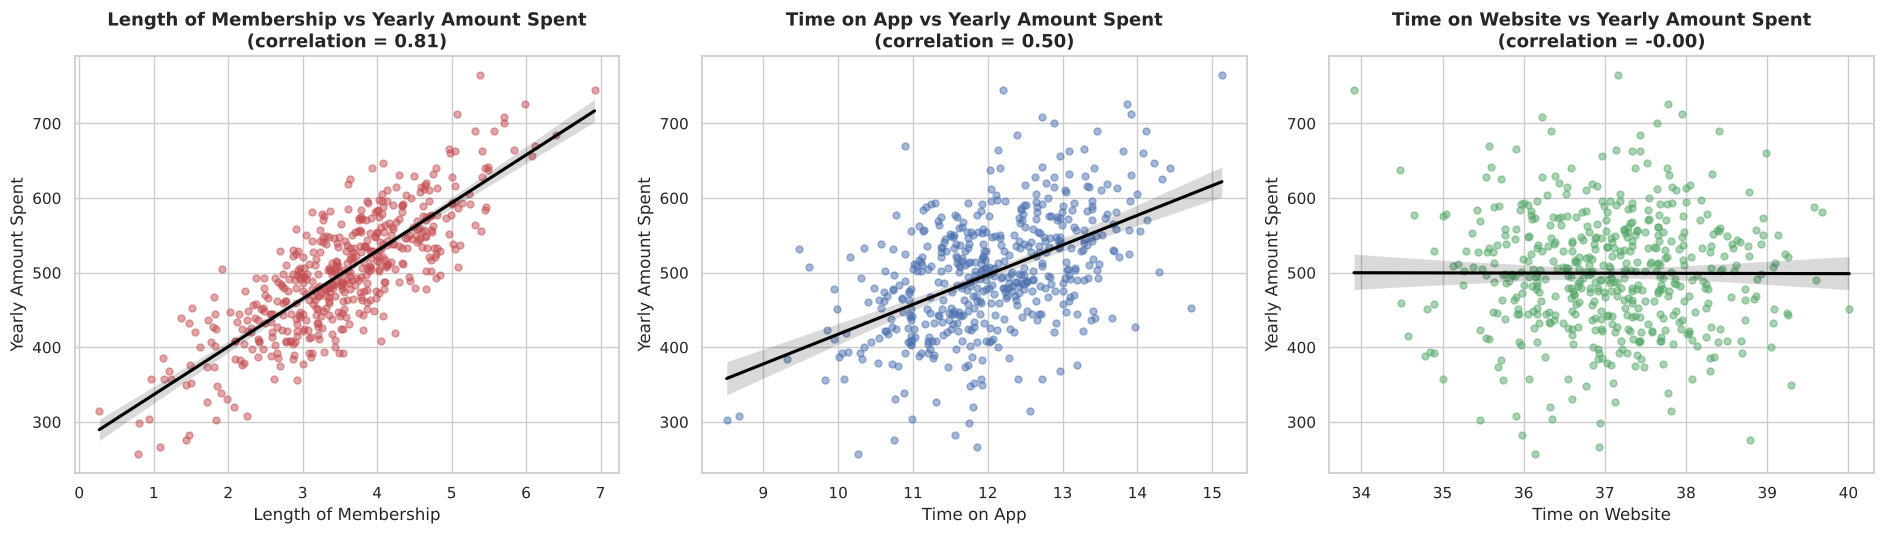

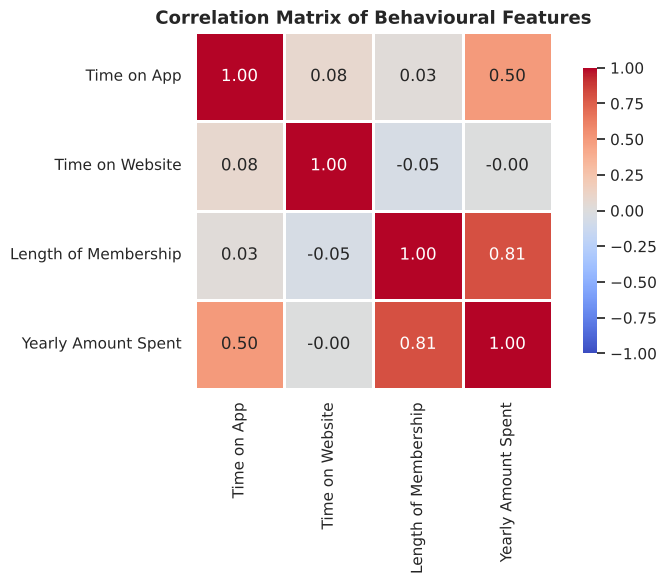

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

pairs = [('Length of Membership', 'Yearly Amount Spent', '#c44e52'),
         ('Time on App', 'Yearly Amount Spent', '#4c72b0'),
         ('Time on Website', 'Yearly Amount Spent', '#55a868')]

for ax, (x, y, c) in zip(axes, pairs):
    sns.regplot(data=df, x=x, y=y, ax=ax, color=c, scatter_kws={'alpha': 0.5, 's': 25}, line_kws={'color': 'black'})
    r = df[x].corr(df[y])
    ax.set_title(f'{x} vs {y}\n(correlation = {r:.2f})')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=1, linecolor='white', square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of Behavioural Features')
plt.tight_layout()
plt.show()

**Observations**

- **Length of Membership has a very strong positive relationship with spending (correlation 0.81).** The longer a customer has been with the company, the more they spend each year. This is the single strongest driver in the data.
- **Time on App has a moderate positive relationship with spending (0.50).** Customers who use the app more spend more.
- **Time on Website has no relationship with spending at all (-0.00).** A flat regression line shows that spending the same amount of time on the website gives no clue about how much someone spends.
- The three behaviour columns are almost uncorrelated with one another (all within +/- 0.08), meaning each one brings its own information. This is a good setup for clustering, since the features are not repeating each other.

## 3. Feature Selection

For clustering I need a small set of behavioural features (2 to 3 works best), each of which says something different about the customer. Based on the analysis above:

| Feature | Decision | Reason |
|---|---|---|
| **Length of Membership** | **Selected** | Captures loyalty / tenure (the stand-in for Recency in RFM). It is also the strongest driver of spending. |
| **Time on App** | **Selected** | Captures how actively the customer engages (the stand-in for Frequency). Moderately linked to spending, and independent of tenure. |
| **Yearly Amount Spent** | **Selected** | The Monetary value of the customer, the most important business measure. |
| Time on Website | Left out | Zero correlation with spending, and it hardly varies from customer to customer (between 34 and 40 minutes), so it would add noise but no useful separation between segments. |
| CLV | Left out | It is calculated from Yearly Amount Spent x Length of Membership, so using it would count the same two features twice. I use it later to *describe* the segments, not to build them. |
| Email, Address, Avatar | Left out | Identifiers or labels, not behaviour. |

So the final features are **Length of Membership, Time on App and Yearly Amount Spent**.

In [9]:
features = ['Length of Membership', 'Time on App', 'Yearly Amount Spent']

# Outlier check on the chosen features (IQR method)
rows = []
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, round(low, 2), round(high, 2), n_out, round(n_out / len(df) * 100, 1)])
pd.DataFrame(rows, columns=['Feature', 'Lower fence', 'Upper fence', 'Outliers', '% of customers'])

,Feature,Lower fence,Upper fence,Outliers,% of customers
0,Length of Membership,1.13,5.93,12,2.4
1,Time on App,9.35,14.80,4,0.8
2,Yearly Amount Spent,288.63,705.72,9,1.8


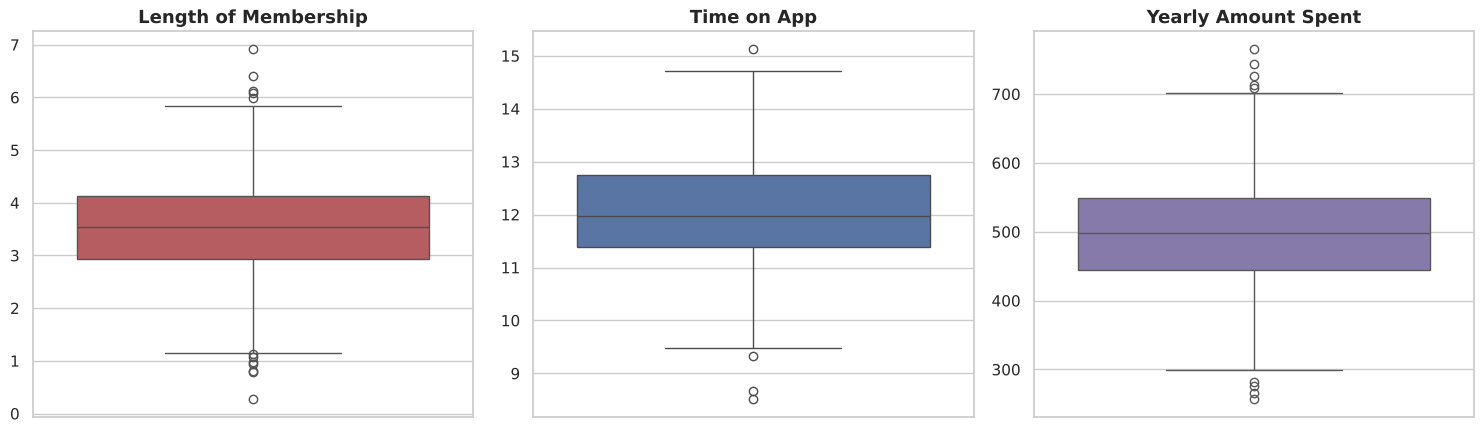

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, c in zip(axes, features, ['#c44e52', '#4c72b0', '#8172b2']):
    sns.boxplot(y=df[col], ax=ax, color=c)
    ax.set_title(col)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Observations**

- A small number of customers fall outside the IQR fences: 12 for Length of Membership, 4 for Time on App and 9 for Yearly Amount Spent (all at or below about 2.4% of the customers).
- I decided to **keep them**. They are not errors; they are genuine customers (for example a very new member, or a very high spender), and these are exactly the kinds of customers a segmentation should be able to identify. Their values are only moderately far from the rest, so they will not distort the clusters badly.

## 4. Standardisation (StandardScaler)

K-Means groups customers by **distance**. The three features are on completely different scales (membership is measured in single-digit years, spending in hundreds), so without scaling, **Yearly Amount Spent would dominate** the distance calculation and the other two features would barely count. `StandardScaler` converts every feature to a mean of 0 and a standard deviation of 1 so that all three get an equal say.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

comparison = pd.DataFrame({
    'Mean (before)': df[features].mean(),
    'Std (before)': df[features].std(ddof=0),
    'Mean (after)': X_scaled_df.mean(),
    'Std (after)': X_scaled_df.std(ddof=0)
}).round(3)
comparison

,Mean (before),Std (before),Mean (after),Std (after)
Length of Membership,3.533,0.998,0.0,1.0
Time on App,12.053,0.993,-0.0,1.0
Yearly Amount Spent,499.314,79.235,0.0,1.0


**Observation:** Before scaling, the spread of the three features is very different (a standard deviation of about 79 for spending against about 1 for the other two). After scaling, every feature has a mean of 0 and a standard deviation of 1, so they are treated equally by K-Means.

## 5. Choosing the Number of Clusters (K): The Elbow Method

K-Means needs to be told how many clusters to look for. The **Elbow Method** runs K-Means for many values of K and plots the **inertia** (the total squared distance between each customer and the centre of its cluster). Inertia always falls as K grows, but at some point adding more clusters stops helping much. That bend in the curve (the "elbow") is a good choice for K.

I also calculate the **silhouette score** (from -1 to 1; higher means customers sit more clearly inside their own cluster) as a second opinion.

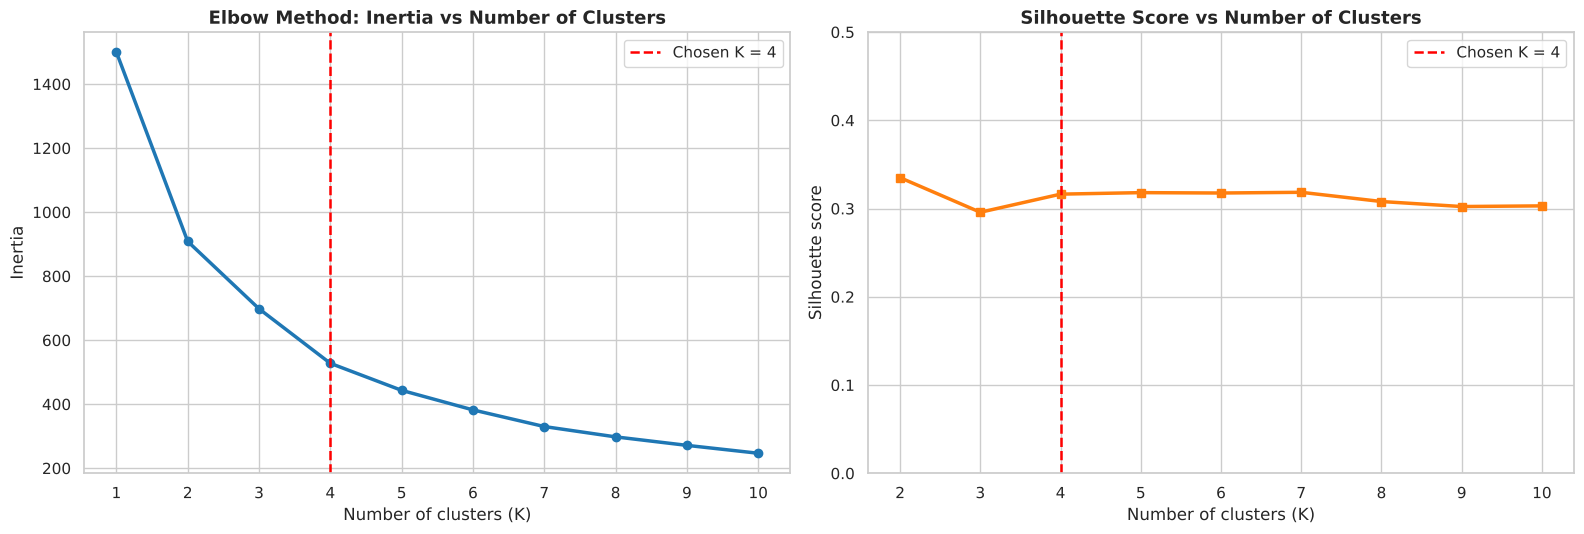

,Inertia,Drop from previous K,Silhouette
K,,,
1,1500.000,NaN,NaN
2,908.544,591.456,0.335
3,698.072,210.472,0.296
4,527.625,170.447,0.316
5,443.185,84.439,0.318
6,382.112,61.074,0.318
7,330.074,52.037,0.318
8,297.831,32.243,0.308
9,271.322,26.509,0.302


In [12]:
inertias, silhouettes = {}, {}
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias[k] = km.inertia_
    if k > 1:
        silhouettes[k] = silhouette_score(X_scaled, km.labels_)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].plot(list(inertias.keys()), list(inertias.values()), marker='o', lw=2.5, color='#1f77b4')
axes[0].axvline(4, color='red', ls='--', lw=1.8, label='Chosen K = 4')
axes[0].set_title('Elbow Method: Inertia vs Number of Clusters')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(range(1, 11))
axes[0].legend()

axes[1].plot(list(silhouettes.keys()), list(silhouettes.values()), marker='s', lw=2.5, color='#ff7f0e')
axes[1].axvline(4, color='red', ls='--', lw=1.8, label='Chosen K = 4')
axes[1].set_title('Silhouette Score vs Number of Clusters')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_xticks(range(2, 11))
axes[1].set_ylim(0, 0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

elbow_table = pd.DataFrame({'Inertia': inertias})
elbow_table['Drop from previous K'] = elbow_table['Inertia'].diff().abs()
elbow_table['Silhouette'] = pd.Series(silhouettes)
elbow_table.index.name = 'K'
elbow_table.round(3)

**Observations and decision: K = 4**

- Inertia falls steeply up to **K = 4** (drops of about 592, 210 and 170 as K goes from 1 to 4), and after that every extra cluster brings a much smaller improvement (the drop is about 84 from K = 4 to K = 5 and keeps shrinking). The elbow is therefore around **K = 4**.
- To be honest, the elbow here is a **gentle bend, not a sharp corner**. This is because the customers form one continuous cloud of behaviour and not clearly separated islands. The silhouette scores (all roughly 0.30 to 0.34) agree: no value of K gives a dramatic jump.
- K = 2 has the highest silhouette score, but two segments (simply "high" and "low") are too coarse to guide different marketing actions. K = 4 has almost the same silhouette score (about 0.32) while giving four groups that a marketing team can realistically work with. Going beyond 4 gives smaller, harder-to-use groups with no real gain.
- I therefore choose **K = 4**, based on the elbow, the silhouette score and business usefulness together.

## 6. Applying K-Means (K = 4)

In [13]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print('Silhouette score for K = 4:', round(silhouette_score(X_scaled, df['Cluster']), 3))
print()
print('Raw cluster numbers and sizes:')
print(df['Cluster'].value_counts().sort_index())

Silhouette score for K = 4: 0.316

Raw cluster numbers and sizes:
Cluster
0    118
1     91
2    136
3    155
Name: count, dtype: int64


K-Means gives the clusters arbitrary numbers (0, 1, 2, 3), which mean nothing to a marketing team. Below I look at the average behaviour of each cluster and give every one a meaningful name. The naming is done by rule: the cluster with the lowest average spend is the *low-spend* group, the one with the highest is the *top* group, and of the two in the middle, the one with more app time is the more *engaged* group.

In [14]:
raw_profile = df.groupby('Cluster')[features].mean()

order = raw_profile['Yearly Amount Spent'].sort_values().index.tolist()   # lowest spend -> highest spend
low, mid1, mid2, high = order

# of the two middle clusters, the one with more app time is the 'Rising Stars'
if raw_profile.loc[mid1, 'Time on App'] > raw_profile.loc[mid2, 'Time on App']:
    rising, loyal = mid1, mid2
else:
    rising, loyal = mid2, mid1

names = {low: 'Low-Spend Newcomers', rising: 'Rising Stars', loyal: 'Loyal Regulars', high: 'Champions'}
df['Segment'] = df['Cluster'].map(names)

SEG_ORDER = ['Low-Spend Newcomers', 'Rising Stars', 'Loyal Regulars', 'Champions']
SEG_COLORS = {'Low-Spend Newcomers': '#d62728', 'Rising Stars': '#ff7f0e',
              'Loyal Regulars': '#1f77b4', 'Champions': '#2ca02c'}

print('Cluster number -> Segment name')
for k, v in sorted(names.items()):
    print(f'  Cluster {k} -> {v}')

Cluster number -> Segment name
  Cluster 0 -> Low-Spend Newcomers
  Cluster 1 -> Champions
  Cluster 2 -> Rising Stars
  Cluster 3 -> Loyal Regulars


## 7. Visualising the Clusters

Three scatter plots, each using a different pair of the clustering features. The black **X** marks show the centre (centroid) of every segment.

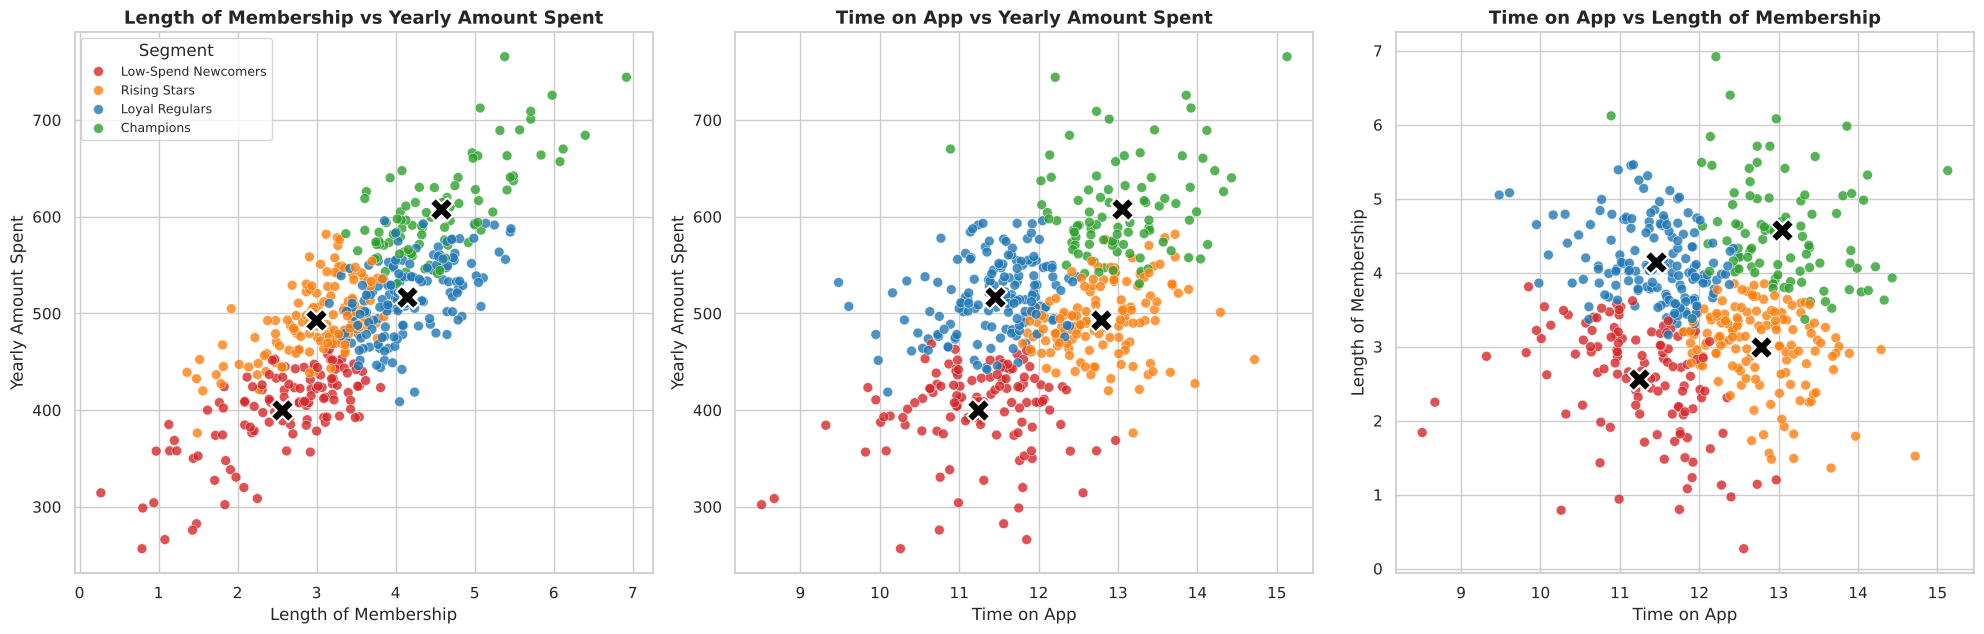

In [15]:
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centroids['Segment'] = centroids.index.map(names)
centroids = centroids.set_index('Segment')

pairs = [('Length of Membership', 'Yearly Amount Spent'),
         ('Time on App', 'Yearly Amount Spent'),
         ('Time on App', 'Length of Membership')]

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for i, (ax, (x, y)) in enumerate(zip(axes, pairs)):
    sns.scatterplot(data=df, x=x, y=y, hue='Segment', hue_order=SEG_ORDER, palette=SEG_COLORS,
                    s=50, alpha=0.8, edgecolor='white', linewidth=0.4, ax=ax)
    ax.scatter(centroids[x], centroids[y], marker='X', s=280, c='black', edgecolor='white',
               linewidth=1.5, zorder=5)
    ax.set_title(f'{x} vs {y}')
    if i > 0:
        ax.get_legend().remove()
    else:
        ax.legend(title='Segment', loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

**Observations**

- **Left chart (Membership vs Spend):** this is where the segments are easiest to see. They form a clear staircase: *Low-Spend Newcomers* sit at the bottom left (short membership, low spend), *Champions* at the top right (long membership, high spend), and the two middle groups sit between them. The upward slope confirms the strong link between loyalty and spending.
- **Middle chart (App vs Spend):** *Champions* and *Rising Stars* sit further to the right, meaning higher app usage, while the other two groups use the app less. This is what separates *Rising Stars* from *Loyal Regulars*, who have a similar spend level but very different app habits.
- **Right chart (App vs Membership):** the segments overlap more here, because these two features are not strongly related to each other. Each segment still occupies a different region.
- The segments **touch and overlap at the edges**. That is natural for a single continuous cloud of customers and matches the moderate silhouette score. The segments are best thought of as practical slices of a continuous scale, not as completely separate groups.

## 8. Profiling Each Cluster

In [16]:
profile = df.groupby('Segment').agg(
    Customers=('Segment', 'size'),
    Avg_Membership_Years=('Length of Membership', 'mean'),
    Avg_Time_on_App=('Time on App', 'mean'),
    Avg_Time_on_Website=('Time on Website', 'mean'),
    Avg_Yearly_Spend=('Yearly Amount Spent', 'mean'),
    Avg_CLV=('CLV', 'mean'),
    Total_Yearly_Revenue=('Yearly Amount Spent', 'sum'),
    Total_CLV=('CLV', 'sum')
).reindex(SEG_ORDER)

profile['% of Customers'] = profile['Customers'] / profile['Customers'].sum() * 100
profile['% of Yearly Revenue'] = profile['Total_Yearly_Revenue'] / profile['Total_Yearly_Revenue'].sum() * 100
profile['% of Total CLV'] = profile['Total_CLV'] / profile['Total_CLV'].sum() * 100

profile.drop(columns=['Total_Yearly_Revenue', 'Total_CLV']).round(2)

,Customers,Avg_Membership_Years,Avg_Time_on_App,Avg_Time_on_Website,Avg_Yearly_Spend,Avg_CLV,% of Customers,% of Yearly Revenue,% of Total CLV
Segment,,,,,,,,,
Low-Spend Newcomers,118,2.56,11.24,37.01,400.20,1047.07,23.6,18.92,13.52
Rising Stars,136,2.99,12.78,37.11,493.09,1487.83,27.2,26.86,22.14
Loyal Regulars,155,4.14,11.45,37.05,516.53,2149.39,31.0,32.07,36.45
Champions,91,4.57,13.05,37.06,607.80,2803.03,18.2,22.15,27.90


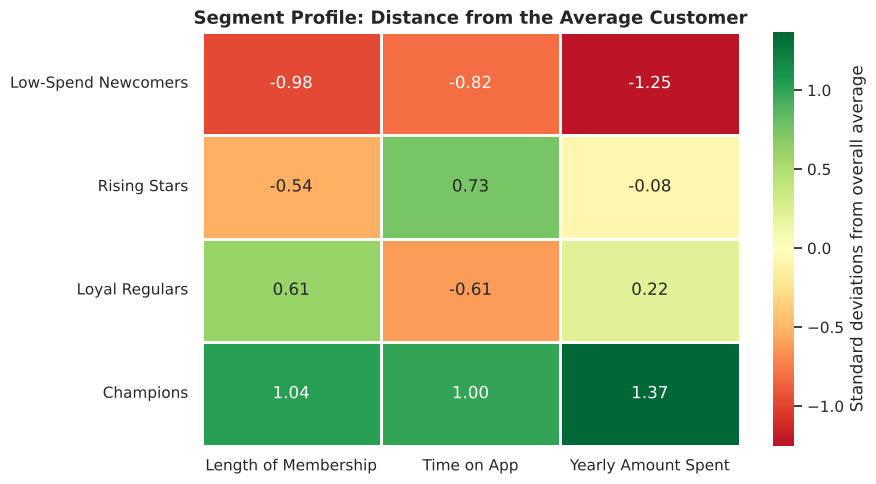

In [17]:
# Heatmap: how each segment compares with the overall average (in standard deviations)
seg_means = df.groupby('Segment')[features].mean().reindex(SEG_ORDER)
z_profile = (seg_means - df[features].mean()) / df[features].std()

plt.figure(figsize=(9, 5))
sns.heatmap(z_profile, annot=True, fmt='.2f', cmap='RdYlGn', center=0, linewidths=1, linecolor='white',
            cbar_kws={'label': 'Standard deviations from overall average'})
plt.title('Segment Profile: Distance from the Average Customer')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Observations**

The table and heatmap show a clear and sensible pattern. Values in the heatmap are in standard deviations from the average customer (green = above average, red = below average).

| Segment | Who they are |
|---|---|
| **Champions** | The best customers: longest membership (about 4.6 years), highest spend (about 608 a year) and the most app time (about 13 minutes). Their average CLV of about 2,800 is the highest of all segments. |
| **Loyal Regulars** | Long-standing members (about 4.1 years) who spend a little above average (about 517) but use the app **less than average** (about 11.4 minutes). They are the biggest segment. |
| **Rising Stars** | Mid-tenure members (about 3.0 years) who are **very active on the app** (about 12.8 minutes) but whose spending (about 493) is still close to average. |
| **Low-Spend Newcomers** | The newest members (about 2.6 years), with the lowest spend (about 400 a year) and the lowest app usage (about 11.2 minutes). Average CLV is only about 1,050. |

Other things to note:

- **Time on Website is almost identical in every segment** (about 37.0 to 37.1 minutes). This confirms the decision to leave it out: it does not separate customers at all.
- **Champions are only 18% of customers but bring about 22% of yearly revenue and about 28% of lifetime value.** Low-Spend Newcomers are 24% of customers but only about 19% of yearly revenue and 14% of lifetime value.
- **Loyal Regulars bring the most revenue of any segment (about 32%)** simply because there are so many of them.

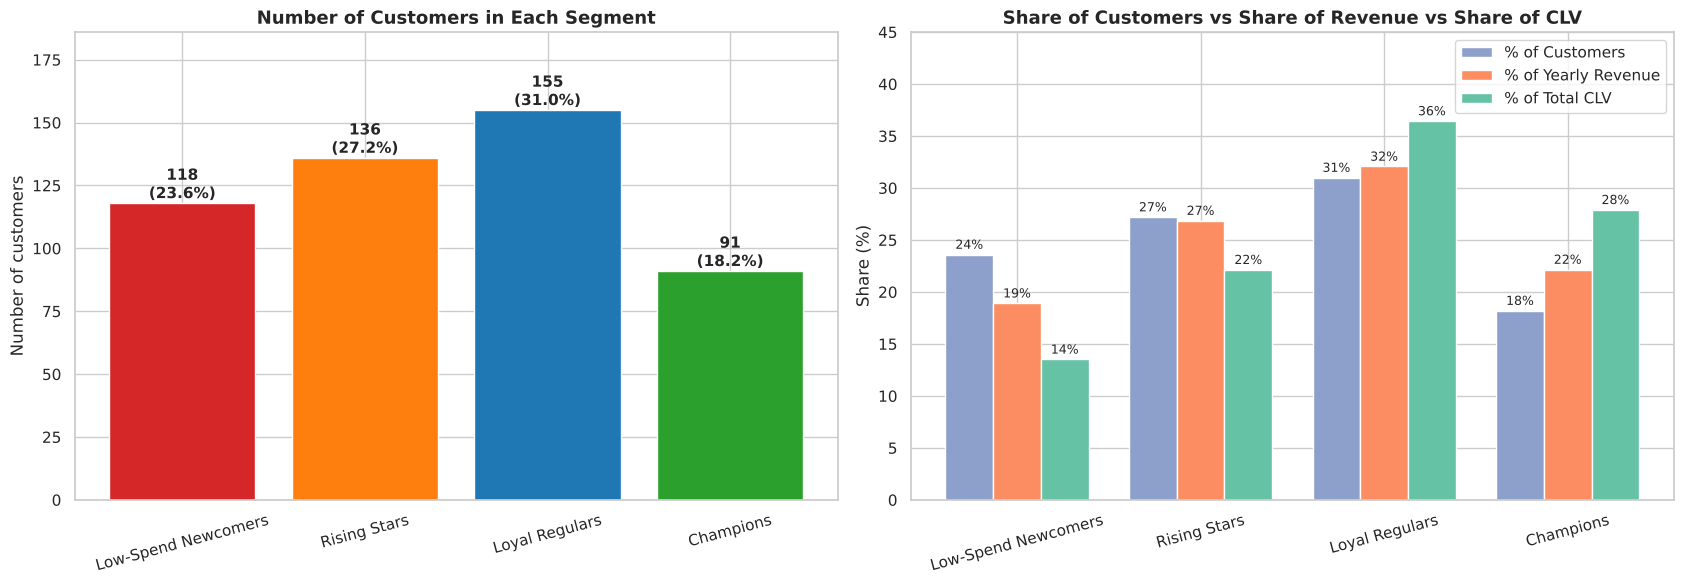

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# 1. number of customers per segment
counts = profile['Customers']
bars = axes[0].bar(counts.index, counts.values, color=[SEG_COLORS[s] for s in counts.index])
for bar, n in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, n + 2, f'{n}\n({n / counts.sum() * 100:.1f}%)',
                 ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Number of Customers in Each Segment')
axes[0].set_ylabel('Number of customers')
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].tick_params(axis='x', rotation=15)

# 2. share of customers vs share of revenue vs share of CLV
share = profile[['% of Customers', '% of Yearly Revenue', '% of Total CLV']]
x = np.arange(len(share))
w = 0.26
for i, (col, c) in enumerate(zip(share.columns, ['#8da0cb', '#fc8d62', '#66c2a5'])):
    b = axes[1].bar(x + (i - 1) * w, share[col], w, label=col, color=c)
    axes[1].bar_label(b, fmt='%.0f%%', padding=2, fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(share.index, rotation=15)
axes[1].set_title('Share of Customers vs Share of Revenue vs Share of CLV')
axes[1].set_ylabel('Share (%)')
axes[1].set_ylim(0, 45)
axes[1].legend()

plt.tight_layout()
plt.show()

**Observations**

- The four segments are all of useful size: **Loyal Regulars are the largest (155 customers, 31%)**, followed by **Rising Stars (136, 27%)**, **Low-Spend Newcomers (118, 24%)** and **Champions (91, 18%)**. No segment is so tiny that it would be hard to target.
- The right-hand chart shows that **value is not spread evenly**: Champions' share of lifetime value (about 28%) is well above their share of customers (18%), while Low-Spend Newcomers show the opposite (24% of customers, only 14% of lifetime value).

## 9. Insights and Marketing Recommendations by Segment

### Champions (91 customers, 18% of customers, about 22% of yearly revenue, about 28% of lifetime value)
**Who they are:** Long-term, high-spending, heavy app users.
**Goal:** Keep them and turn them into advocates.
- Create a **VIP / premium loyalty tier** with early access to new products, free priority shipping and exclusive offers.
- Launch a **referral programme**. These customers love the brand and their friends are likely to look like them.
- **Avoid heavy discounting**. They already buy a lot, so discounts would simply reduce profit. Reward them with status and experiences instead.
- *Track:* retention rate, number of referrals.

### Loyal Regulars (155 customers, 31% of customers, about 32% of yearly revenue)
**Who they are:** Long-standing members with decent spending, but **below-average app usage**.
**Goal:** Grow their spend by getting them onto the app.
- In this data, app time is positively linked with higher spending (correlation about 0.50), and this is the largest group that under-uses the app. That makes them the **biggest growth opportunity**.
- Offer **app-only perks** (for example a small discount for the first app purchase, app-exclusive deals) and send **push-notification reminders** and personalised recommendations.
- Use **bundles and upsell offers** to raise the value of each order.
- *Track:* app adoption and time on app, change in yearly spend.

### Rising Stars (136 customers, 27% of customers, about 27% of yearly revenue)
**Who they are:** Mid-tenure customers who are **highly engaged on the app** but whose spending has not caught up yet.
**Goal:** Convert engagement into spending and move them towards Champion status.
- They already like the product, so use **cross-sell and personalised recommendations** (for example "frequently bought together" suggestions).
- Introduce a **points-based loyalty programme** where spending faster unlocks rewards sooner.
- Give them a small push with **limited-time offers** to increase the size of their basket.
- Their tenure is still growing, which means they are likely to move into the Champions group over time if they are nurtured well.
- *Track:* growth in yearly spend, share who reach Champion level.

### Low-Spend Newcomers (118 customers, 24% of customers, about 19% of yearly revenue, about 14% of lifetime value)
**Who they are:** The shortest memberships, lowest spend and lowest app usage.
**Goal:** Activate them early, before they drift away.
- Run a proper **onboarding journey**: welcome email series, style guides and a **second-purchase incentive**.
- **Encourage app download** with a welcome offer, since app engagement is linked to higher spending.
- Use **low-cost channels** such as email and social media, and avoid expensive campaigns because this is the lowest-value group.
- Offer free shipping above a spending threshold to raise the order value gradually.
- *Track:* second-purchase rate, app activation, spend growth in the first year.

### One finding that applies to everyone
Time on the website has **no link with spending** and is the same in every segment. Based on this data, marketing and development budget is better spent on **improving the app experience** than on getting people to stay longer on the website. (This should be tested before budgets are cut, since the data shows association, not cause.)

## 10. Saving the Segments

So the marketing team can actually use the result, I save every customer with their segment name to a CSV file.

In [19]:
export_cols = ['Email', 'Segment', 'Length of Membership', 'Time on App', 'Time on Website',
               'Yearly Amount Spent', 'CLV']
df[export_cols].sort_values(['Segment', 'Yearly Amount Spent'], ascending=[True, False]).to_csv(
    'customer_segments.csv', index=False)
print('Saved: customer_segments.csv')
df[export_cols].head()

Saved: customer_segments.csv


,Email,Segment,Length of Membership,Time on App,Time on Website,Yearly Amount Spent,CLV
0,mstephenson@fernandez.com,Champions,4.08,12.66,39.58,587.95,2398.8360
1,hduke@hotmail.com,Low-Spend Newcomers,2.66,11.11,37.27,392.20,1043.2520
2,pallen@yahoo.com,Loyal Regulars,4.10,11.33,37.11,487.55,1998.9550
3,riverarebecca@gmail.com,Rising Stars,3.12,13.72,36.72,581.85,1815.3720
4,mstephens@davidson-herman.com,Champions,4.45,12.80,37.54,599.41,2667.3745


## 11. Conclusion

This project used K-Means clustering on 500 customers of an e-commerce company to build data-driven segments. After cleaning the data (including a hidden tab character in a column name), I selected three behavioural features, **Length of Membership, Time on App and Yearly Amount Spent**, standardised them and used the Elbow Method together with the silhouette score to choose **K = 4**.

The four segments are **Champions, Loyal Regulars, Rising Stars and Low-Spend Newcomers**. They differ in loyalty, engagement and value:

- **Loyalty drives spending**: membership length has a correlation of 0.81 with yearly spend, which is why the segments line up so neatly along it.
- **App engagement matters, website time does not**: app time is moderately linked to spend (0.50), while website time shows no relationship at all (about 0.00) and is identical across all segments.
- **Value is concentrated**: Champions are 18% of customers but about 28% of lifetime value.
- The biggest **growth opportunity** is the large *Loyal Regulars* group, which is loyal but under-uses the app, while *Rising Stars* are the best pipeline for future Champions.

Each segment has its own recommended action (Section 9), from VIP programmes for Champions to onboarding journeys for Newcomers.

### Limitations
- **No order-level data.** A true RFM analysis (with recency and purchase frequency) was not possible, so Length of Membership and Time on App were used as proxies. CLV is a simple historical estimate that assumes spending stayed constant.
- **The clusters overlap.** The customers form a continuous cloud and the silhouette score is moderate (about 0.32), so the segments are practical groupings, not sharply separated groups.
- **Only a few behavioural features** were available, and there is no data on product categories, returns or churn.
- Relationships found here are correlations, not proven causes. The recommendations should be tested with small pilot campaigns (for example, an A/B test of an app-only offer for Loyal Regulars) before a full rollout.

---
*End of analysis. Prepared by Saurabh Shukla (saurabhshuklant@gmail.com).*